In [1]:
%%writefile -a ../src/swap.py


def simulate_swap_mtm(times, rates, a, b, sigma, fixed_rate, maturity, freq, notional=1_000_000):
    """MtM del swap en todas las fechas y escenarios simulados (tabla n_paths x n_fechas)."""
    mtm = np.zeros_like(rates)
    dt_sim = times[1] - times[0]

    for i, t in enumerate(times):
        t_reset = np.floor(t * freq + 1e-9) / freq      # última fecha de reajuste
        j = int(round(t_reset / dt_sim))                # su columna en la tabla de tasas
        mtm[:, i] = swap_mtm(t, rates[:, i], rates[:, j], a, b, sigma,
                             fixed_rate, maturity, freq, notional)
    return mtm

Appending to ../src/swap.py


In [2]:
%%writefile ../src/exposure.py
import numpy as np


def exposure(mtm):
    """Exposición = max(MtM, 0): solo perdés si te deben."""
    return np.maximum(mtm, 0)


def expected_exposure(mtm):
    """EE: promedio de la exposición en cada fecha."""
    return exposure(mtm).mean(axis=0)


def potential_future_exposure(mtm, q=0.95):
    """PFE: percentil q de la exposición en cada fecha."""
    return np.quantile(exposure(mtm), q, axis=0)


def expected_positive_exposure(ee):
    """EPE: promedio de la EE a lo largo del tiempo (fechas equiespaciadas)."""
    return ee.mean()

Writing ../src/exposure.py


In [3]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.rates import simulate_vasicek
from src.swap import par_swap_rate, swap_mtm

In [4]:
# Vasicek
r0, a, b, sigma = 0.03, 0.5, 0.04, 0.01

# Simulación
T, n_steps, n_paths = 5, 60, 10_000
times, rates = simulate_vasicek(r0, a, b, sigma, T, n_steps, n_paths, seed=42)

In [5]:
# Swap: 5 años, pagos semestrales, 1.000.000 de nocional
maturity = 5
freq = 2
notional = 1_000_000

K = par_swap_rate(r0, a, b, sigma, maturity, freq)
print(f"Tasa fija par (K): {K:.4%}")

mtm_0 = swap_mtm(0, np.array([r0]), np.array([r0]), a, b, sigma, K, maturity, freq, notional)
print(f"MtM en t=0: {mtm_0[0]:,.2f}")

Tasa fija par (K): 3.6441%
MtM en t=0: 0.00


In [6]:
mtm = np.zeros_like(rates)
dt_sim = T / n_steps

for i, t in enumerate(times):
    t_reset = np.floor(t * freq + 1e-9) / freq      # última fecha de reajuste
    j = int(round(t_reset / dt_sim))                # su columna en la tabla de tasas
    mtm[:, i] = swap_mtm(t, rates[:, i], rates[:, j], a, b, sigma, K, maturity, freq, notional)

print(mtm.shape)

(10000, 61)


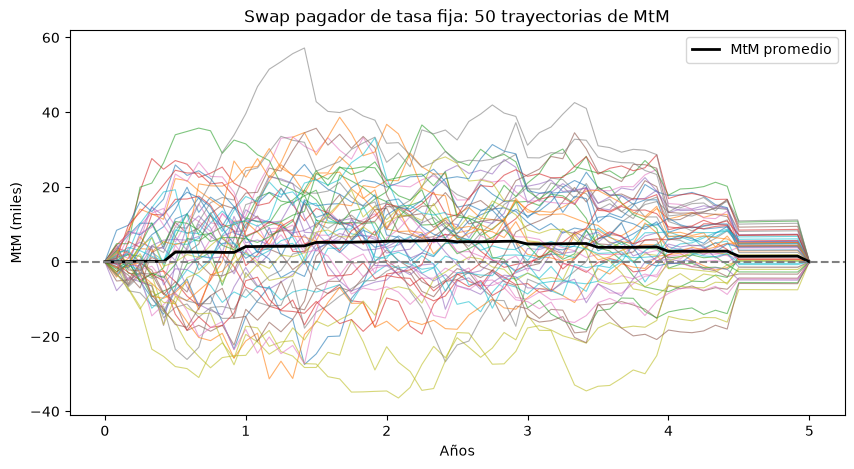

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, mtm[:50].T / 1_000, lw=0.8, alpha=0.6)
ax.plot(times, mtm.mean(axis=0) / 1_000, color="black", lw=2, label="MtM promedio")
ax.axhline(0, color="gray", ls="--")
ax.set_xlabel("Años")
ax.set_ylabel("MtM (miles)")
ax.set_title("Swap pagador de tasa fija: 50 trayectorias de MtM")
ax.legend()
fig.savefig("../reports/figures/swap_mtm_paths.png", dpi=150, bbox_inches="tight")
plt.show()